# Tarea 16 · Estilo común y exportación de gráficos

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/julianschmidt1/tpi-analisis-de-datos/blob/feat/16-estilo-graficos/notebooks/trabajo/16_estilo_graficos.ipynb)

**TPI · Introducción al Análisis de Datos · UTN FRA · División 343**  
**Integrantes:** Matías, Julián y Emmanuel. **Responsable de esta tarea:** Matías.

Definimos la paleta, los tamaños y las fuentes para las visualizaciones del TPI, junto con una función para exportar figuras a `reports/figures/`. La celda de la sección 1 se puede copiar completa a los notebooks de las tareas 17, 18 y 19. Incluimos un gráfico de ejemplo con la proporción general de churn y su interpretación.

## Cómo ejecutarlo

- **Local:** instalar las dependencias de `requirements.txt`, abrir el notebook desde el repositorio, reiniciar el entorno y ejecutar todas las celdas. Se busca la raíz del proyecto desde el directorio actual y sus padres.
- **Colab:** abrir el badge, reiniciar el entorno y ejecutar todas las celdas. El ejemplo carga el CSV publicado en GitHub, sin montar Drive ni clonar el repositorio. La imagen generada queda en `reports/figures/` dentro del panel **Archivos** y se puede descargar desde allí.
- La configuración y la exportación funcionan sin cargar datos. Para el ejemplo se intenta leer `telco_clean.csv`; mientras la tarea 9 no esté integrada, se utiliza `telco_provisorio.csv` y se identifica la fuente provisoria en el gráfico. Solo la ausencia del archivo limpio habilita esa alternativa; otros errores de lectura se informan.
- El badge apunta a la rama `feat/16-estilo-graficos` para la revisión y estará disponible tras el push. Al integrar la tarea, actualizar el enlace a `main`.


## 1. Celda común para copiar a los demás notebooks

**Copiar toda la siguiente celda y ejecutarla antes de crear los gráficos.** Incluye las importaciones, la detección de la raíz, las constantes de estilo y las funciones `aplicar_estilo()` y `guardar_figura(fig, nombre)`.

- **Colores:** usamos una paleta con tonos diferenciados; `No` siempre es azul y `Yes` siempre es naranja. Se deben conservar las etiquetas de texto para que el color no sea la única referencia. Para correlaciones se propone `vlag`, una escala divergente que se debe centrar en cero con límites de −1 a 1.
- **Tamaño y tipografía:** figura base de 9 × 5 pulgadas, fuente DejaVu Sans, títulos de 14 puntos, etiquetas de 12 y marcas de 11. El tamaño se puede ampliar cuando haya muchas categorías o varios paneles.
- **Lectura:** fondo blanco, cuadrícula tenue y sin bordes superior y derecho. Las barras parten de cero y las tasas se muestran en porcentaje.
- **Exportación:** PNG a 300 dpi, fondo blanco y ajuste de márgenes. El nombre debe incluir el número de tarea, sin ruta ni extensión; por ejemplo, `17_histograma_tenure`. La función recibe la figura explícitamente y devuelve la ruta guardada. Si se repite el nombre, reemplaza la imagen anterior, lo que permite regenerar los resultados.

El estilo se puede restablecer con `aplicar_estilo()` si otra celda lo modifica. Al integrar el notebook final, esta configuración se ejecutará una sola vez al principio de la sección de visualización.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

try:
    import google.colab
except ImportError:
    EN_COLAB = False
else:
    EN_COLAB = True

if EN_COLAB:
    RAIZ = Path.cwd()
else:
    actual = Path.cwd().resolve()
    RAIZ = next(
        (ruta for ruta in (actual, *actual.parents) if (ruta / 'PLAN_TAREAS.md').is_file()),
        None,
    )
    if RAIZ is None:
        raise FileNotFoundError('Abrí Jupyter dentro del repositorio del TPI.')

TAMANO_FIGURA = (9, 5)
DPI_EXPORTACION = 300
PALETA_CATEGORICA = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
COLORES_CHURN = {'No': '#0072B2', 'Yes': '#D55E00'}
MAPA_CORRELACION = 'vlag'
CARPETA_FIGURAS = RAIZ / 'reports' / 'figures'

def aplicar_estilo():
    """Aplica el estilo común del TPI a las figuras que se creen después."""
    sns.set_theme(
        style='whitegrid',
        context='notebook',
        font='DejaVu Sans',
        palette=PALETA_CATEGORICA,
        rc={
            'figure.figsize': TAMANO_FIGURA,
            'figure.dpi': 110,
            'figure.facecolor': 'white',
            'axes.facecolor': 'white',
            'axes.titlesize': 14,
            'axes.titleweight': 'bold',
            'axes.labelsize': 12,
            'xtick.labelsize': 11,
            'ytick.labelsize': 11,
            'legend.fontsize': 11,
            'axes.spines.top': False,
            'axes.spines.right': False,
            'grid.alpha': 0.25,
            'savefig.dpi': DPI_EXPORTACION,
            'savefig.facecolor': 'white',
        },
    )

def guardar_figura(fig, nombre):
    """Guarda fig en reports/figures/<nombre>.png a 300 dpi y devuelve Path.

    Usar un nombre sin ruta ni extensión, como '17_histograma_tenure'.
    Un nombre existente se sobrescribe para permitir regenerar el gráfico.
    Guardar antes de plt.show() y cerrar luego con plt.close(fig).
    """
    if not nombre or Path(nombre).name != nombre or Path(nombre).suffix:
        raise ValueError('Usá un nombre sin ruta ni extensión.')
    CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
    ruta = CARPETA_FIGURAS / f'{nombre}.png'
    fig.savefig(ruta, dpi=DPI_EXPORTACION, bbox_inches='tight', facecolor='white')
    return ruta

aplicar_estilo()
print('Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.')


Estilo común aplicado. Exportación PNG a 300 dpi en reports/figures/.


## 2. Datos para demostrar el estilo

El ejemplo calcula las proporciones de `Churn` sobre el dataset limpio cuando esté disponible y, mientras tanto, sobre el provisorio acordado en el plan. Mostramos la fuente y la cantidad de clientes para que se pueda reconocer el alcance del gráfico. Se verifica el dominio de la variable objetivo antes de calcular las proporciones: no se descartan etiquetas desconocidas o faltantes silenciosamente.


In [2]:
from urllib.error import HTTPError

import pandas as pd

GITHUB_REPO = 'julianschmidt1/tpi-analisis-de-datos'
GITHUB_REF = 'main'
RUTA_LIMPIA = Path('data/processed/telco_clean.csv')
RUTA_PROVISORIA = Path('data/processed/telco_provisorio.csv')

def leer_datos(ruta):
    if EN_COLAB:
        url = (
            f'https://raw.githubusercontent.com/{GITHUB_REPO}/'
            f'{GITHUB_REF}/{ruta.as_posix()}'
        )
        return pd.read_csv(url)
    return pd.read_csv(RAIZ / ruta)

try:
    df = leer_datos(RUTA_LIMPIA)
    ruta_datos = RUTA_LIMPIA
    fuente_provisoria = False
except (FileNotFoundError, HTTPError) as error:
    if isinstance(error, HTTPError) and error.code != 404:
        raise
    df = leer_datos(RUTA_PROVISORIA)
    ruta_datos = RUTA_PROVISORIA
    fuente_provisoria = True

assert not df.empty, 'El ejemplo requiere clientes para calcular proporciones.'
assert df['Churn'].isin(['No', 'Yes']).all(), 'Revisá las etiquetas de Churn.'
conteos = df['Churn'].value_counts().reindex(['No', 'Yes'], fill_value=0)
proporciones = conteos / conteos.sum()
print(f'Fuente: {ruta_datos.as_posix()}')
print(f'Clientes analizados: {len(df):,}')
print(f'Fuente provisoria: {fuente_provisoria}')


Fuente: data/processed/telco_provisorio.csv
Clientes analizados: 7,043
Fuente provisoria: True


## 3. Ejemplo de gráfico y exportación

Dibujamos la proporción general de permanencia y abandono. Usamos los colores semánticos, etiquetas en español, un eje porcentual que comienza en cero y anotaciones con las tasas. La nota inferior identifica el archivo y el tamaño de la muestra. `guardar_figura` recibe `fig`, se ejecuta antes de mostrarla y guarda `reports/figures/16_ejemplo_churn.png`.


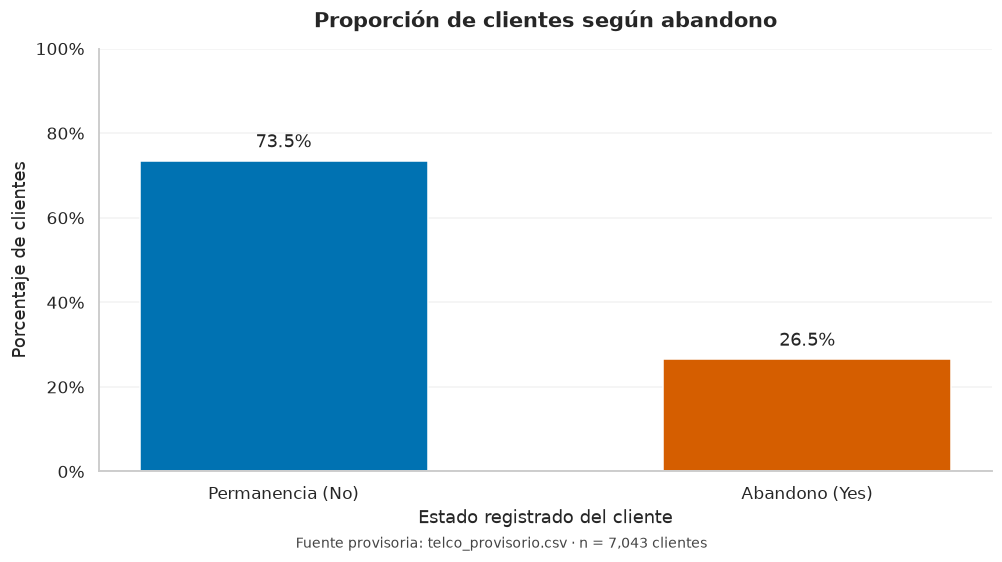

Figura exportada: reports/figures/16_ejemplo_churn.png
Churn observado en la fuente: 26.5%


In [3]:
fig, ax = plt.subplots(layout='constrained')
barras = ax.bar(
    ['Permanencia (No)', 'Abandono (Yes)'],
    proporciones.to_numpy(),
    color=[COLORES_CHURN['No'], COLORES_CHURN['Yes']],
    width=0.55,
)
ax.set_title('Proporción de clientes según abandono', pad=14)
ax.set_xlabel('Estado registrado del cliente')
ax.set_ylabel('Porcentaje de clientes')
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.xaxis.grid(False)
ax.bar_label(barras, labels=[f'{valor:.1%}' for valor in proporciones], padding=6)
estado_fuente = 'provisoria' if fuente_provisoria else 'limpia'
fig.supxlabel(
    f'Fuente {estado_fuente}: {ruta_datos.name} · n = {len(df):,} clientes',
    fontsize=9,
    color='#444444',
)

ruta_figura = guardar_figura(fig, '16_ejemplo_churn')
plt.show()
plt.close(fig)
print(f'Figura exportada: {ruta_figura.relative_to(RAIZ).as_posix()}')
print(f'Churn observado en la fuente: {proporciones.loc["Yes"]:.1%}')


### Interpretación del ejemplo

En el archivo provisorio actual, aproximadamente el **26,5 %** de los 7.043 clientes tiene `Churn = Yes` y el **73,5 %** tiene `Churn = No`. Hay más clientes con permanencia registrada, por lo que el conteo de aciertos de un futuro clasificador deberá compararse con la línea base de predecir siempre la clase mayoritaria, como pide la tarea 27.

Este gráfico describe la composición de la muestra; no identifica causas de abandono ni demuestra la efectividad de una campaña. Cuando se genere el dataset limpio, se debe revisar la interpretación con las tasas que imprima la celda anterior. La imagen se regenera automáticamente usando la fuente limpia si está disponible.


## 4. Cómo reutilizarlo en las tareas 17 a 19

1. Copiar la celda completa de la sección 1 al principio del notebook propio y ejecutarla.
2. Cargar los datos de la tarea y crear una figura con `fig, ax = plt.subplots()`.
3. Dibujar el gráfico usando `ax`. Para comparar `Churn`, conservar `COLORES_CHURN`; para un heatmap de correlación, usar `MAPA_CORRELACION` con `vmin=-1`, `vmax=1`, `center=0` y anotaciones.
4. Agregar título, nombres de ejes y unidades. Para tasas expresadas entre 0 y 1, usar `PercentFormatter(xmax=1)` y comenzar las barras en cero. Si las tasas se expresan entre 0 y 100, usar `xmax=100`.
5. Ejecutar `guardar_figura(fig, '17_histograma_tenure')` con un nombre propio de la tarea; luego `plt.show()` y `plt.close(fig)`.
6. Escribir una interpretación de negocio después del gráfico y aclarar si la fuente es provisoria.

La celda común no depende del DataFrame del ejemplo y no modifica los datos. La función guarda la figura que recibe, incluso cuando hay varias figuras abiertas. Las tareas 17, 18 y 19 desarrollarán los histogramas, el heatmap y las tasas por segmento; la tarea 20 revisará la coherencia visual del conjunto.
